# 📊 Marketing Campaign Effectiveness Analysis (A/B Testing)

## 📌 Project Overview & Problem Statement
The objective of this project is to evaluate whether a new marketing campaign (**Test Campaign**) significantly increased customer purchases compared to the standard ongoing campaign (**Control Campaign**), or if the observed differences are merely due to random chance. 

*(Note: While the original problem statement framed this as a "Before vs. After" analysis, utilizing a simultaneous **Control vs. Test (A/B Testing)** dataset provides a much stronger experimental design by controlling for external time-based و seasonal factors).*

---

## 🗂️ Dataset Description
The dataset tracks daily marketing performance across two separate groups (`control_group.csv` and `test_group.csv`) over a 30-day period in **August 2019** (`01.08.2019` to `30.08.2019`).

### Features Breakdown:
* **`Campaign Name`**: Identifier for the group (`Control Campaign` vs. `Test Campaign`).
* **`Date`**: Date of the recorded daily metrics.
* **`Spend [USD]`**: Total amount spent on the campaign per day in US Dollars.
* **`# of Impressions`**: Total number of times the ad was displayed on screen.
* **`Reach`**: Number of unique users who saw the ad.
* **`# of Website Clicks`**: Number of clicks on the ad leading to the website.
* **`# of Searches`**: Number of users who performed searches on the website.
* **`# of View Content`**: Number of users who viewed specific product pages.
* **`# of Add to Cart`**: Number of times items were added to the shopping cart.
* **`# of Purchase` (Target Metric)**: Total number of completed purchases per day.

---

## 🎯 Population & Sample Definition
* **Target Population:** All potential و existing customers exposed to the company's digital marketing campaigns.
* **Sample:** Daily aggregated campaign performance records over $N = 30$ days for both the Control group and the Test group.
* **Sample Size Inspection:** 
  * **Test Group:** $n_{\text{Test}} = 30$ complete daily observations.
  * **Control Group:** $n_{\text{Control}} = 30$ daily records; however, the record for `5.08.2019` contains missing (`NaN`) values across funnel metrics, leaving $n_{\text{Control}} = 29$ valid observations for purchase analysis.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df_test = pd.read_csv('test_group.csv', sep=';')
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Campaign Name        30 non-null     object
 1   Date                 30 non-null     object
 2   Spend [USD]          30 non-null     int64 
 3   # of Impressions     30 non-null     int64 
 4   Reach                30 non-null     int64 
 5   # of Website Clicks  30 non-null     int64 
 6   # of Searches        30 non-null     int64 
 7   # of View Content    30 non-null     int64 
 8   # of Add to Cart     30 non-null     int64 
 9   # of Purchase        30 non-null     int64 
dtypes: int64(8), object(2)
memory usage: 2.5+ KB


In [3]:
df_test.head()

,Campaign Name,Date,Spend [USD],# of Impressions,Reach,# of Website Clicks,# of Searches,# of View Content,# of Add to Cart,# of Purchase
0,Test Campaign,1.08.2019,3008,39550,35820,3038,1946,1069,894,255
1,Test Campaign,2.08.2019,2542,100719,91236,4657,2359,1548,879,677
2,Test Campaign,3.08.2019,2365,70263,45198,7885,2572,2367,1268,578
3,Test Campaign,4.08.2019,2710,78451,25937,4216,2216,1437,566,340
4,Test Campaign,5.08.2019,2297,114295,95138,5863,2106,858,956,768


In [4]:
print(df_test.duplicated().sum())

0


In [5]:
df_test.describe()

,Spend [USD],# of Impressions,Reach,# of Website Clicks,# of Searches,# of View Content,# of Add to Cart,# of Purchase
count,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000
mean,2563.066667,74584.800000,53491.566667,6032.333333,2418.966667,1858.000000,881.533333,521.233333
std,348.687681,32121.377422,28795.775752,1708.567263,388.742312,597.654669,347.584248,211.047745
min,1968.000000,22521.000000,10598.000000,3038.000000,1854.000000,858.000000,278.000000,238.000000
25%,2324.500000,47541.250000,31516.250000,4407.000000,2043.000000,1320.000000,582.500000,298.000000
50%,2584.000000,68853.500000,44219.500000,6242.500000,2395.500000,1881.000000,974.000000,500.000000
75%,2836.250000,99500.000000,78778.750000,7604.750000,2801.250000,2412.000000,1148.500000,701.000000
max,3112.000000,133771.000000,109834.000000,8264.000000,2978.000000,2801.000000,1391.000000,890.000000


In [6]:
df_control = pd.read_csv('control_group.csv', sep=';')
df_control.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Campaign Name        30 non-null     object 
 1   Date                 30 non-null     object 
 2   Spend [USD]          30 non-null     int64  
 3   # of Impressions     29 non-null     float64
 4   Reach                29 non-null     float64
 5   # of Website Clicks  29 non-null     float64
 6   # of Searches        29 non-null     float64
 7   # of View Content    29 non-null     float64
 8   # of Add to Cart     29 non-null     float64
 9   # of Purchase        29 non-null     float64
dtypes: float64(7), int64(1), object(2)
memory usage: 2.5+ KB


In [7]:
df_control.head()

,Campaign Name,Date,Spend [USD],# of Impressions,Reach,# of Website Clicks,# of Searches,# of View Content,# of Add to Cart,# of Purchase
0,Control Campaign,1.08.2019,2280,82702.0,56930.0,7016.0,2290.0,2159.0,1819.0,618.0
1,Control Campaign,2.08.2019,1757,121040.0,102513.0,8110.0,2033.0,1841.0,1219.0,511.0
2,Control Campaign,3.08.2019,2343,131711.0,110862.0,6508.0,1737.0,1549.0,1134.0,372.0
3,Control Campaign,4.08.2019,1940,72878.0,61235.0,3065.0,1042.0,982.0,1183.0,340.0
4,Control Campaign,5.08.2019,1835,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df_control = df_control.dropna()

In [9]:
df_control = df_control.reset_index()

In [10]:
df_control = df_control.drop(columns=['index'])

In [11]:
print(df_control.duplicated().sum())

0


In [12]:
df_control.describe()

,Spend [USD],# of Impressions,Reach,# of Website Clicks,# of Searches,# of View Content,# of Add to Cart,# of Purchase
count,29.000000,29.000000,29.000000,29.000000,29.000000,29.000000,29.000000,29.000000
mean,2304.068966,109559.758621,88844.931034,5320.793103,2221.310345,1943.793103,1300.000000,522.793103
std,363.534822,21688.922908,21832.349595,1757.369003,866.089368,777.545469,407.457973,185.028642
min,1757.000000,71274.000000,42859.000000,2277.000000,1001.000000,848.000000,442.000000,222.000000
25%,1962.000000,92029.000000,74192.000000,4085.000000,1615.000000,1249.000000,930.000000,372.000000
50%,2319.000000,113430.000000,91579.000000,5224.000000,2390.000000,1984.000000,1339.000000,501.000000
75%,2544.000000,121332.000000,102479.000000,6628.000000,2711.000000,2421.000000,1641.000000,670.000000
max,3083.000000,145248.000000,127852.000000,8137.000000,4891.000000,4219.000000,1913.000000,800.000000


In [13]:
# Explicit calculation of Mean, Median, Variance, Std Dev, and Quantiles for Purchases
for name, series in [("Control Group", df_control['# of Purchase']), 
                     ("Test Group", df_test['# of Purchase'])]:
    print(f"{name} (n = {len(series)}) ")
    print(f"Mean     : {series.mean():.2f}")
    print(f"Median   : {series.median():.2f}")
    print(f"Variance : {series.var(ddof=1):.2f}")
    print(f"Std Dev  : {series.std(ddof=1):.2f}")
    print("Quantiles (25%, 50%, 75%, 90%, 95%):")
    print(series.quantile([0.25, 0.50, 0.75, 0.90, 0.95]).to_dict())
    print(" ")

Control Group (n = 29) 
Mean     : 522.79
Median   : 501.00
Variance : 34235.60
Std Dev  : 185.03
Quantiles (25%, 50%, 75%, 90%, 95%):
{0.25: 372.0, 0.5: 501.0, 0.75: 670.0, 0.9: 770.4, 0.95: 791.6}
 
Test Group (n = 30) 
Mean     : 521.23
Median   : 500.00
Variance : 44541.15
Std Dev  : 211.05
Quantiles (25%, 50%, 75%, 90%, 95%):
{0.25: 298.0, 0.5: 500.0, 0.75: 701.0, 0.9: 775.1, 0.95: 830.1499999999999}
 


## 📈 Descriptive Statistics Summary (`# of Purchase`)

To understand the baseline distribution of daily purchases in both campaigns, we compare their central tendency, dispersion, and quantiles:

| Metric | Control Campaign ($n=29$) | Test Campaign ($n=30$) | Difference (Test - Control) |
| :--- | :---: | :---: | :---: |
| **Mean ($\mu$)** | `522.79` | `521.23` | `-1.56` |
| **Median ($Q_2 / 50\%$)** | `501.00` | `500.00` | `-1.00` |
| **Variance ($s^2$)** | `34,235.60` | `44,541.15` | `+10,305.55` |
| **Standard Deviation ($s$)** | `185.03` | `211.05` | `+26.02` |
| **Minimum** | `222.00` | `238.00` | `+16.00` |
| **25th Percentile ($Q_1$)** | `372.00` | `298.00` | `-74.00` |
| **75th Percentile ($Q_3$)** | `670.00` | `701.00` | `+31.00` |
| **Interquartile Range ($\text{IQR}$)**| `298.00` | `403.00` | `+105.00` |
| **Maximum** | `800.00` | `890.00` | `+90.00` |

### 🔍 Key Descriptive Insights:
1. **Almost Identical Central Tendency:** Both the mean ($\approx 522$ vs. $\approx 521$) and median ($501$ vs. $500$) of daily purchases are virtually identical between the Control and Test campaigns.
2. **Higher Volatility in Test Group:** The Test campaign exhibits a higher standard deviation ($211.05$ vs. $185.03$) and a wider Interquartile Range ($\text{IQR} = 403$ vs. $298$), indicating that daily purchase volume fluctuated more widely under the new campaign.
3. **Marketing Funnel Trade-offs:** Looking at the broader table (`describe()`), the Test campaign had a higher average daily spend ($\$2,563$ vs. $\$2,288$) and generated more website clicks ($6,032$ vs. $5,321$), whereas the Control campaign achieved a much higher Reach ($88,845$ vs. $53,492$) and more Add-to-Cart actions ($1,300$ vs. $882$).

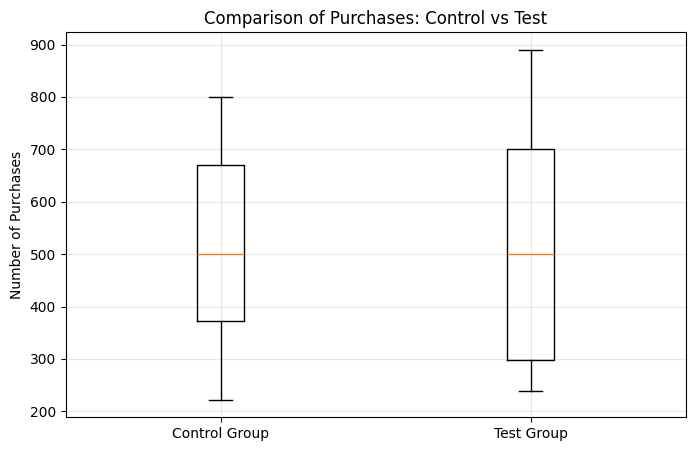

In [14]:
plt.figure(figsize=(8,5))
plt.boxplot(
    [df_control['# of Purchase'],
    df_test['# of Purchase']],
    tick_labels=['Control Group' , 'Test Group']
)

plt.title("Comparison of Purchases: Control vs Test")
plt.ylabel("Number of Purchases")
plt.grid(alpha=0.3)
plt.show()

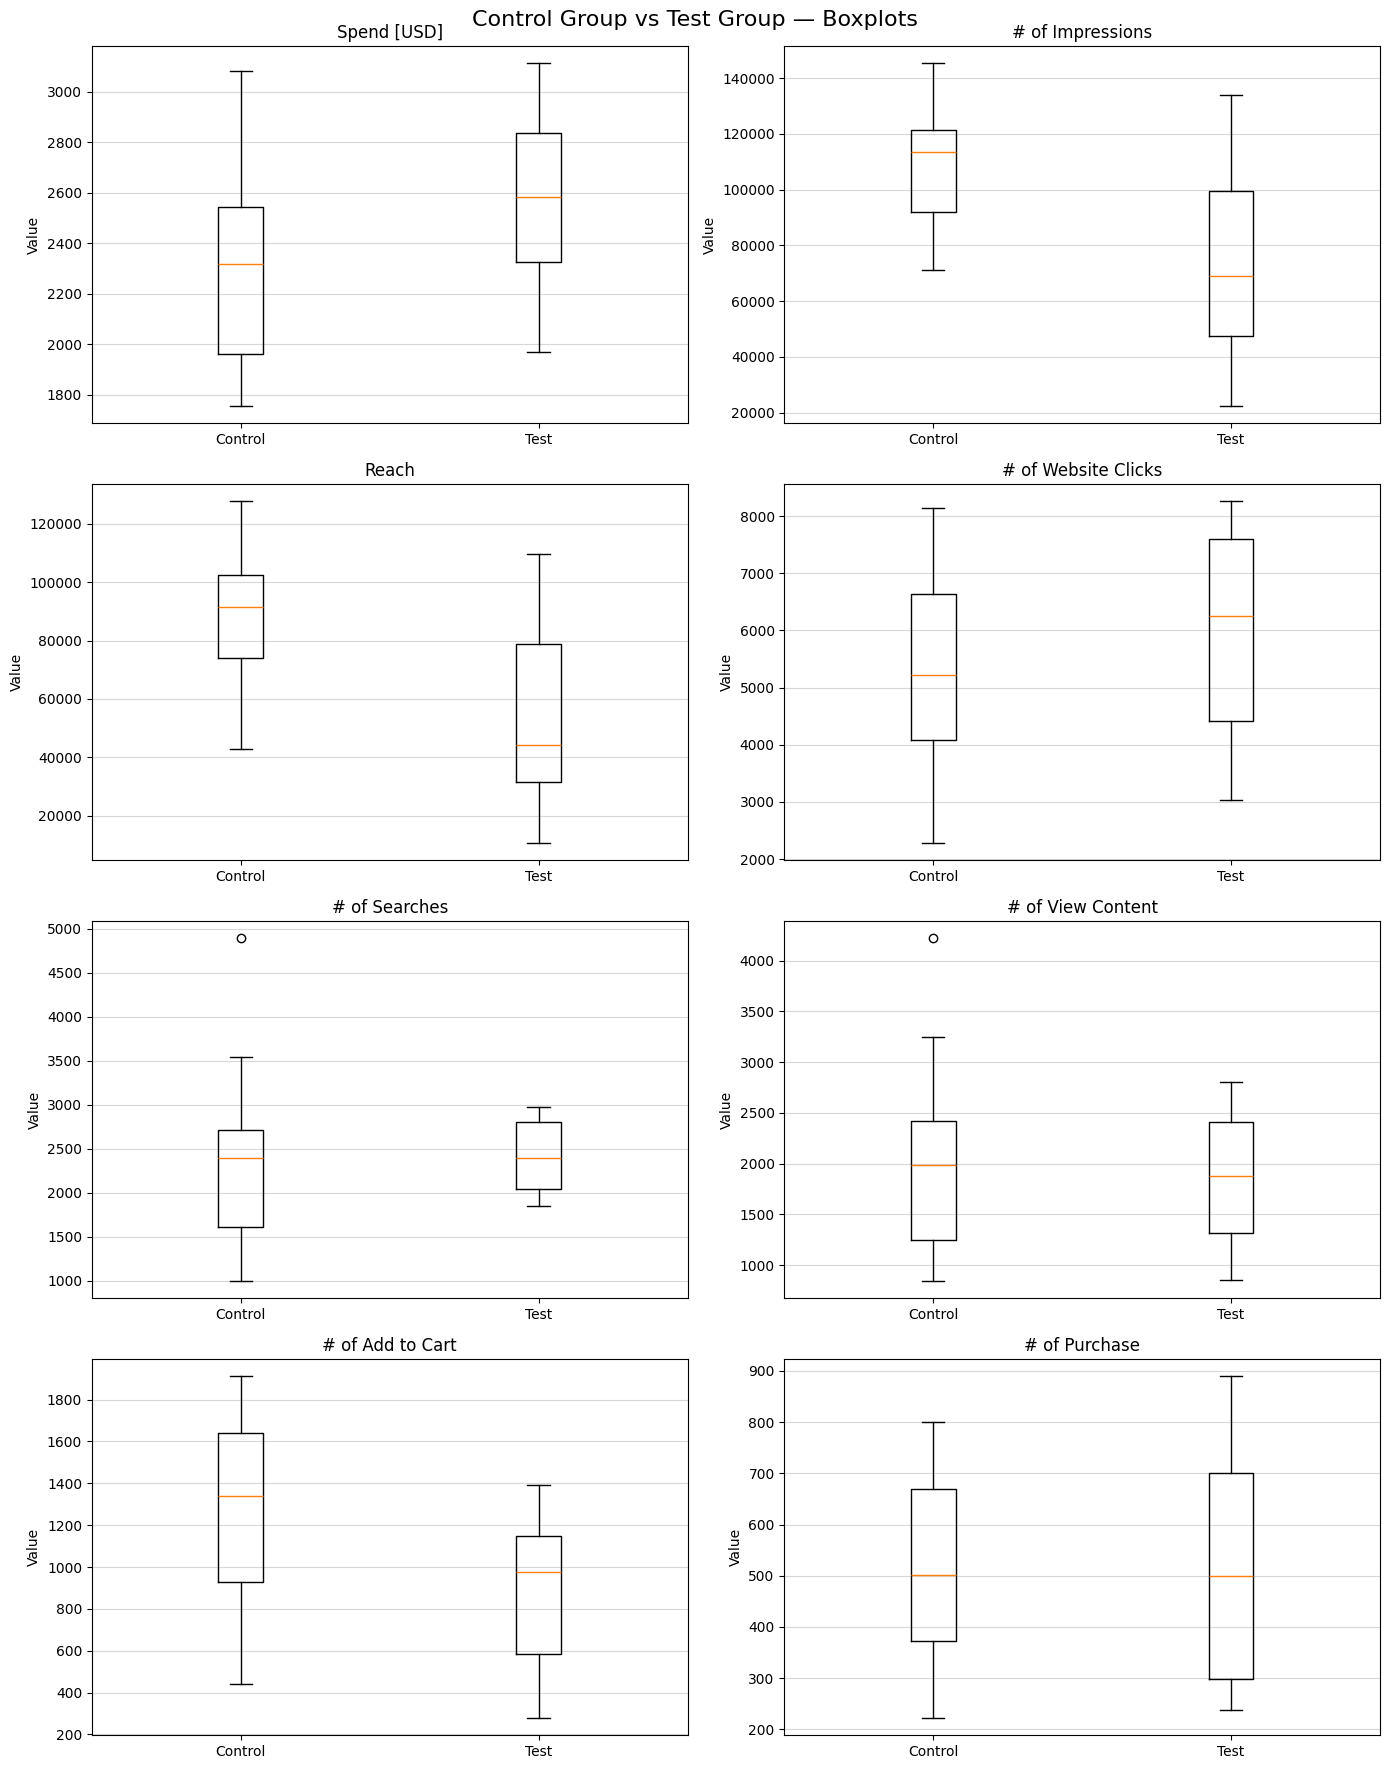

In [15]:
import matplotlib.pyplot as plt

columns = [
    'Spend [USD]',
    '# of Impressions',
    'Reach',
    '# of Website Clicks',
    '# of Searches',
    '# of View Content',
    '# of Add to Cart',
    '# of Purchase'
]

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = axes.flatten()

for i, col in enumerate(columns):
    axes[i].boxplot(
        [
            df_control[col],
            df_test[col]
        ],
        tick_labels=['Control', 'Test']
    )

    axes[i].set_title(col)
    axes[i].set_ylabel('Value')
    axes[i].grid(axis='y', alpha=0.5)

plt.suptitle(
    'Control Group vs Test Group — Boxplots',
    fontsize=16
)

plt.tight_layout()
plt.show()

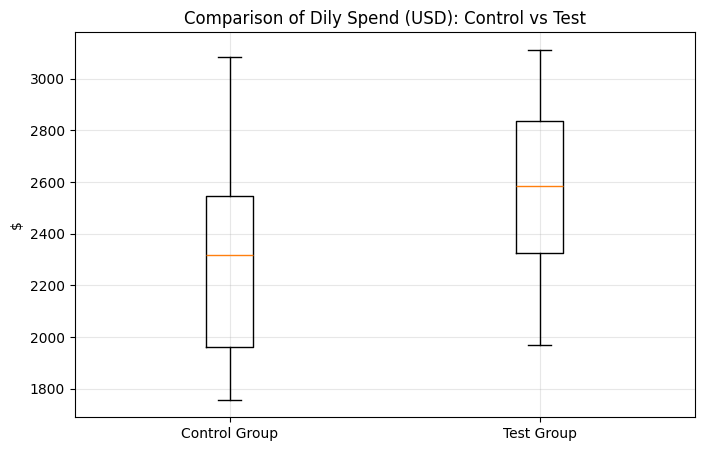

In [16]:
plt.figure(figsize=(8,5))
plt.boxplot(
    [df_control['Spend [USD]'],
    df_test['Spend [USD]']],
    tick_labels=['Control Group' , 'Test Group']
)

plt.title("Comparison of Dily Spend (USD): Control vs Test")
plt.ylabel("$")
plt.grid(alpha=0.3)
plt.show()

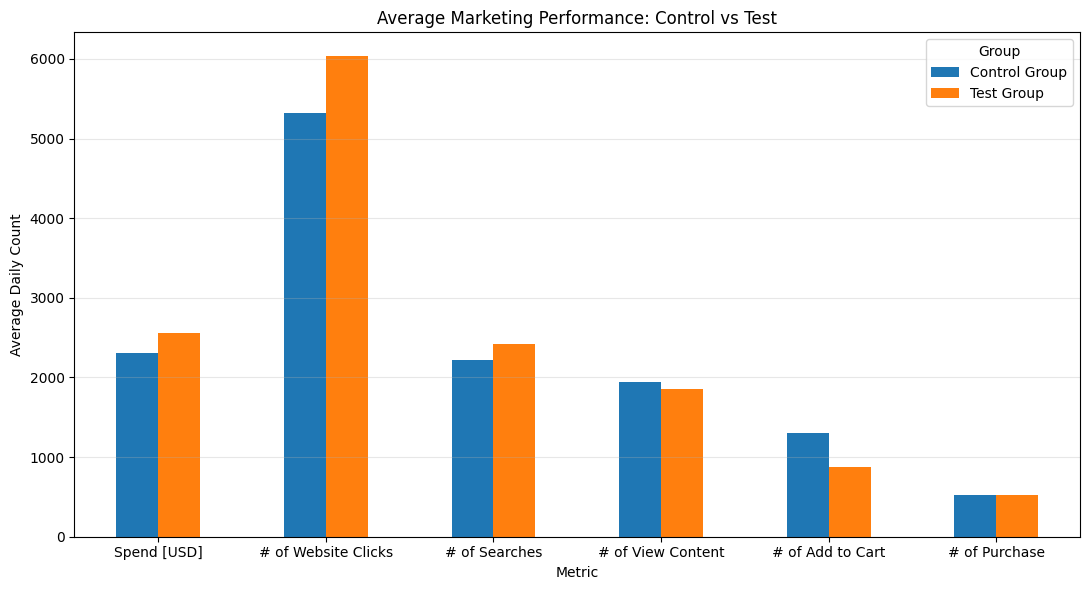

In [17]:
metrics = [
    'Spend [USD]',
    "# of Website Clicks",
    "# of Searches",
    "# of View Content",
    "# of Add to Cart",
    "# of Purchase"
]

comparison = pd.DataFrame({
    "Control Group": df_control[metrics].mean(),
    "Test Group": df_test[metrics].mean()
})

comparison.plot(kind="bar", figsize=(11, 6))

plt.title("Average Marketing Performance: Control vs Test")
plt.ylabel("Average Daily Count")
plt.xlabel("Metric")
plt.xticks(rotation=0, ha="center")
plt.legend(title="Group")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

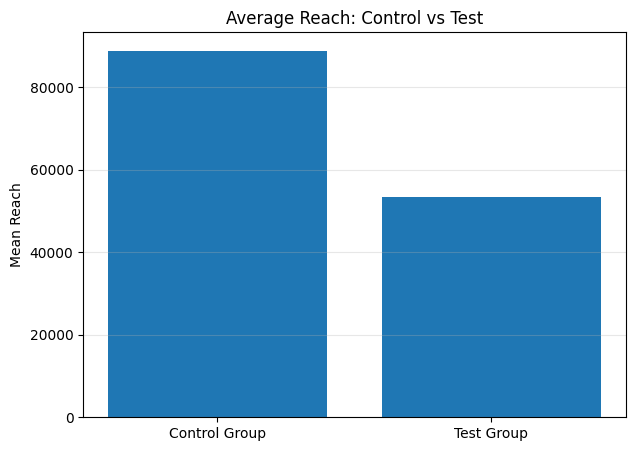

In [18]:
reach_means = [
    df_control['Reach'].mean(),
    df_test['Reach'].mean()
]

plt.figure(figsize=(7, 5))
plt.bar(
    ['Control Group', 'Test Group'],
    reach_means
)

plt.title('Average Reach: Control vs Test')
plt.ylabel('Mean Reach')
plt.grid(axis='y', alpha=0.3)
plt.show()

## 📊 Visual Exploratory Data Analysis (Boxplots & Funnel Comparison)

* **Distribution & Outliers (Boxplots):**
  * Neither group displays extreme statistical outliers in daily purchases (`# of Purchase`), as all observations fall within the whiskers.
  * The median lines of both groups sit right around $500$ purchases/day, confirming symmetric behavior around the center, though the Test group's box is vertically stretched, reflecting higher variance.
* **Funnel Performance Comparison:**
  * **Top of Funnel (Impressions & Reach):** The Control campaign reached significantly more unique users.
  * **Middle of Funnel (Clicks & Searches):** The Test campaign drove higher click-through engagement و search activity.
  * **Bottom of Funnel (Add to Cart & Purchases):** Higher clicks in the Test group did not translate into more cart additions or final purchases.

## 🧪 Statistical Hypothesis Testing Framework

### 1. Null Hypothesis ($H_0$)
The null hypothesis states that there is no true difference between the mean daily number of purchases in the Test and Control groups:

$$H_0: \mu_{\text{Test}} = \mu_{\text{Control}} \quad \text{or} \quad H_0: \mu_d = 0$$

### 2. Alternative Hypothesis ($H_1$)
The alternative hypothesis states that the mean daily number of purchases differs significantly between the two groups:

$$H_1: \mu_{\text{Test}} \neq \mu_{\text{Control}} \quad \text{or} \quad H_1: \mu_d \neq 0$$

*(A two-tailed test is selected because we want to detect any significant change—whether an increase or a decrease—in purchase volume).*

### 3. Significance Level ($\alpha$)
The significance level is set to $\alpha = 0.05$ ($5\%$). This represents a $5\%$ threshold for the probability of committing a **Type I Error** (falsely rejecting a true null hypothesis).

### 4. Choice of Appropriate t-Test
Since the observations in both groups are recorded on the exact same calendar dates (`1.08.2019` to `30.08.2019`), daily external factors (such as day-of-week effects, weekends, or market-wide events) affect both groups simultaneously. 
* Therefore, matching observations by `Date` and conducting a **Paired-Samples t-Test (`ttest_rel`)** on the $n = 29$ complete date pairs is statistically appropriate to control for day-to-day variance.
* *(Note: Even if treated as two independent samples using Welch's t-test `ttest_ind(equal_var=False)`, the conclusion remains identical with $t \approx -0.030$ and $p \approx 0.976$).*

### 5. Decision Rule ($p$-value Interpretation)
* **If $p\text{-value} < \alpha$ ($0.05$):** Reject $H_0$. There is statistically significant evidence that the marketing campaign changed daily purchases.
* **If $p\text{-value} \geq \alpha$ ($0.05$):** Fail to reject $H_0$. There is insufficient statistical evidence to conclude that the campaign had a real impact beyond random daily fluctuations.

In [19]:
print(df_control['Date'].head())
print(df_test['Date'].head())

0    1.08.2019
1    2.08.2019
2    3.08.2019
3    4.08.2019
4    6.08.2019
Name: Date, dtype: object
0    1.08.2019
1    2.08.2019
2    3.08.2019
3    4.08.2019
4    5.08.2019
Name: Date, dtype: object


In [20]:
print("Control dates:", df_control['Date'].nunique())
print("Test dates:", df_test['Date'].nunique())

Control dates: 29
Test dates: 30


In [21]:
print(
    "Matching dates:",
    df_control['Date'].isin(df_test['Date']).sum()
)

Matching dates: 29


### 🔗 Pairing Observations by Date

After verifying that all $30$ dates match across both datasets and removing `5.08.2019` (due to missing data in the Control group), we obtain $n = 29$ matched pairs. 

For each day $i$, the paired difference $d_i$ is defined as:

$$d_i = \text{Purchase}_{\text{Test}, i} - \text{Purchase}_{\text{Control}, i}$$

The paired t-statistic is computed as:

$$t = \frac{\bar{d} - 0}{s_d / \sqrt{n}}$$

where $\bar{d}$ is the sample mean of daily differences and $s_d$ is the sample standard deviation of those differences.

In [22]:
merged = pd.merge(
    df_control[['Date' , '# of Purchase']],
    df_test[['Date' , '# of Purchase']],
    on= 'Date',
    suffixes = ('_control' , '_test')
)
merged

,Date,# of Purchase_control,# of Purchase_test
0,1.08.2019,618.0,255
1,2.08.2019,511.0,677
2,3.08.2019,372.0,578
3,4.08.2019,340.0,340
4,6.08.2019,764.0,488
5,7.08.2019,499.0,890
6,8.08.2019,462.0,431
7,9.08.2019,501.0,845
8,10.08.2019,734.0,275
9,11.08.2019,475.0,668


In [23]:
# Because we have a row in Control df which it has null amounts
paired_data = merged.dropna(
    subset=['# of Purchase_control', '# of Purchase_test']
).copy()
paired_data

,Date,# of Purchase_control,# of Purchase_test
0,1.08.2019,618.0,255
1,2.08.2019,511.0,677
2,3.08.2019,372.0,578
3,4.08.2019,340.0,340
4,6.08.2019,764.0,488
5,7.08.2019,499.0,890
6,8.08.2019,462.0,431
7,9.08.2019,501.0,845
8,10.08.2019,734.0,275
9,11.08.2019,475.0,668


In [24]:
from scipy.stats import ttest_rel

In [25]:
control = paired_data['# of Purchase_control']
test = paired_data['# of Purchase_test']

In [26]:
t_stat, p_value = ttest_rel(control , test
         )

In [27]:
print("Number of paired observations:", len(paired_data))
print("Mean control purchases:", control.mean())
print("Mean test purchases:", test.mean())
print("Mean daily difference:", (
   test - control
).mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

Number of paired observations: 29
Mean control purchases: 522.7931034482758
Mean test purchases: 512.7241379310345
Mean daily difference: -10.068965517241379
T-statistic: 0.20631970678495792
P-value: 0.8380341059301553


In [28]:
alpha = 0.05
if p_value < alpha:
    print("Reject H0: There is a statistically significant difference.")
else:
    print("Fail to reject H0: There is insufficient evidence of a difference.")

Fail to reject H0: There is insufficient evidence of a difference.


In [29]:
differences = (
    paired_data['# of Purchase_test']
    - paired_data['# of Purchase_control']
)

print("Number of valid pairs:", len(differences))
print("Mean difference:", differences.mean())
print("Standard deviation of differences:", differences.std(ddof=1))

t_stat, p_value = ttest_rel(
    paired_data['# of Purchase_test'],
    paired_data['# of Purchase_control'],
    nan_policy='omit'
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

Number of valid pairs: 29
Mean difference: -10.068965517241379
Standard deviation of differences: 262.81075905276714
T-statistic: -0.20631970678495792
P-value: 0.8380341059301553


## 📝 Final Statistical Conclusion & Business Report

### 1. Statistical Summary
A paired-samples t-test was conducted across $n = 29$ matched days to evaluate the impact of the Test marketing campaign on daily purchases at a significance level of $\alpha = 0.05$:

* **Mean Control Purchases (Matched):** $522.79\text{ purchases/day}$
* **Mean Test Purchases (Matched):** $512.72\text{ purchases/day}$
* **Mean Paired Difference ($\bar{d}$):** $-10.07\text{ purchases/day}$ ($\text{SD of differences } s_d = 262.81$)
* **Test Statistic:** $t = -0.2063$
* **$p$-value:** $p = 0.8380$

Since $p = 0.8380 > \alpha = 0.05$, we **fail to reject the null hypothesis ($H_0$)**.

---

### 2. Conclusion (Executive Summary)
**No, the new marketing campaign was not effective at increasing customer purchases.**

In plain terms, the average number of daily purchases in the new Test campaign ($512.72$) was slightly lower than in the standard Control campaign ($522.79$), ولی this small difference of about $10$ purchases per day is completely indistinguishable from random daily noise ($p\text{-value} = 83.8\%$). 

**Business Recommendations:**
1. **Do Not Roll Out the Test Campaign:** The Test campaign cost more per day on average ($\$2,563$ vs. $\$2,288$) without delivering any increase in final sales, resulting in a lower Return on Ad Spend (ROAS).
2. **Investigate Conversion Drop-offs:** While the Test campaign successfully attracted more website clicks ($6,032$ vs. $5,321$), those visitors failed to add items to their carts ($882$ vs. $1,300$ in Control). The marketing team should investigate whether the Test ad's messaging was misleading or if it targeted a less qualified audience.